In [99]:
import pandas as pd

In [100]:
data = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/Heart.csv")
data.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [101]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   Age         303 non-null    int64  
 2   Sex         303 non-null    int64  
 3   ChestPain   303 non-null    str    
 4   RestBP      303 non-null    int64  
 5   Chol        303 non-null    int64  
 6   Fbs         303 non-null    int64  
 7   RestECG     303 non-null    int64  
 8   MaxHR       303 non-null    int64  
 9   ExAng       303 non-null    int64  
 10  Oldpeak     303 non-null    float64
 11  Slope       303 non-null    int64  
 12  Ca          299 non-null    float64
 13  Thal        301 non-null    str    
 14  AHD         303 non-null    str    
dtypes: float64(2), int64(10), str(3)
memory usage: 35.6 KB


In [102]:
data.dropna(inplace=True)

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

In [104]:
def chkOutliers(data, column):
    plt.figure(figsize=(7,3))
    plt.subplot(1,2,1)  #row size, column size, plot no
    plt.boxplot(data[column])
    plt.subplot(1,2,2)
    m = data[column].mean()
    std = data[column].std()
    sns.histplot(data[column], kde=True)
    plt.axvline(m, color='green')
    plt.axvline(m - 3 * std, color='red')
    plt.axvline(m + 3 * std, color='red')
    plt.show()

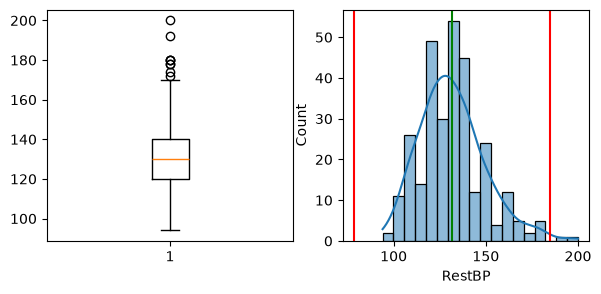

In [105]:
chkOutliers(data, 'RestBP')

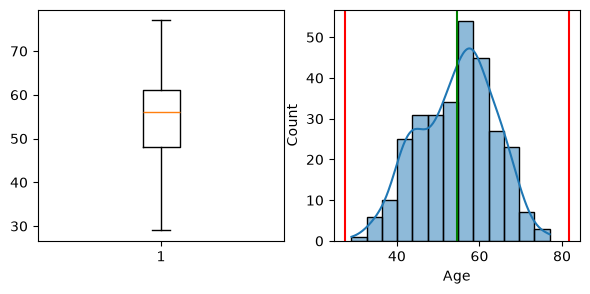

In [106]:
chkOutliers(data, 'Age')

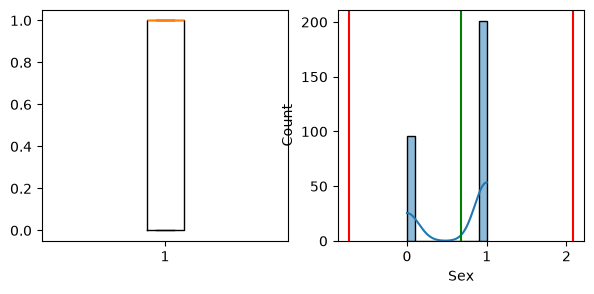

In [107]:
chkOutliers(data, 'Sex')

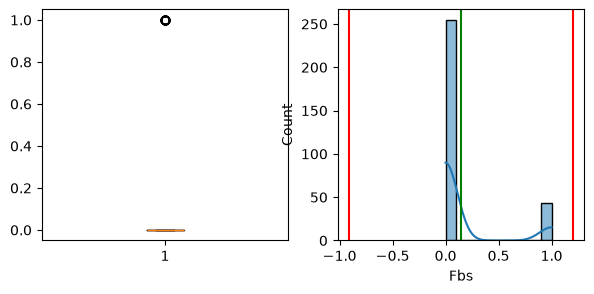

In [108]:
chkOutliers(data, 'Fbs')

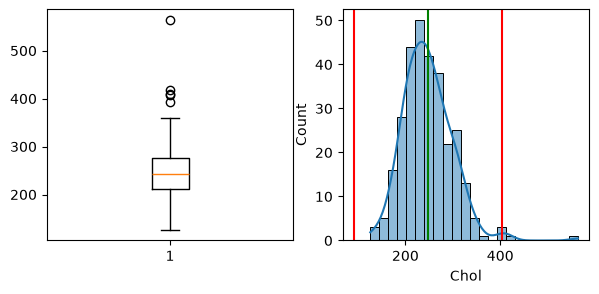

In [109]:
chkOutliers(data, 'Chol')

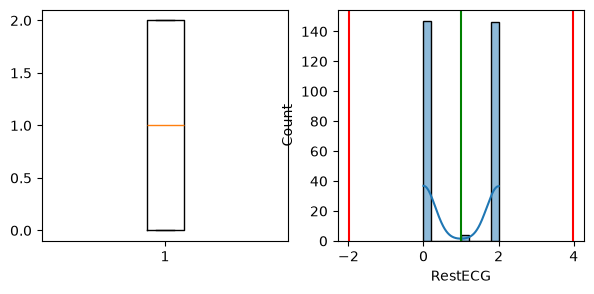

In [110]:
chkOutliers(data, 'RestECG')

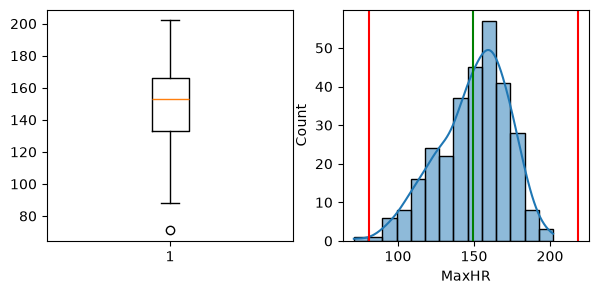

In [111]:
chkOutliers(data, 'MaxHR')

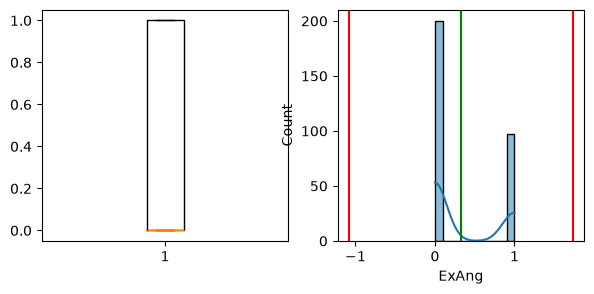

In [112]:
chkOutliers(data, 'ExAng')

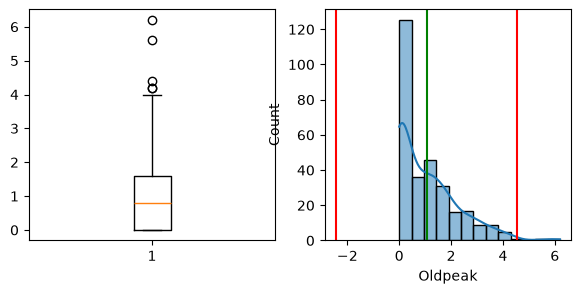

In [113]:
chkOutliers(data, 'Oldpeak')

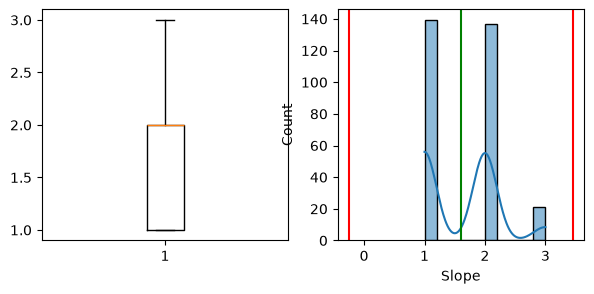

In [114]:
chkOutliers(data, 'Slope')

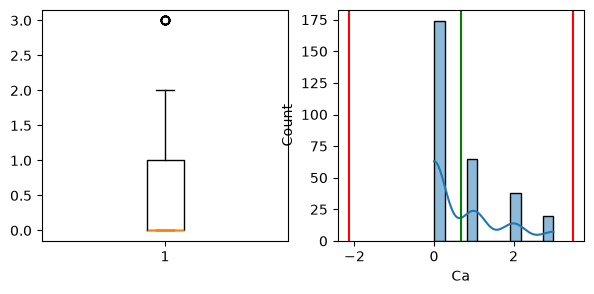

In [115]:
chkOutliers(data, 'Ca')

In [164]:
def replaceOutliers(data, column):
    q3 = data[column].quantile(0.75)
    q1 = data[column].quantile(0.25)
    iqr = q3 - q1
    ub = q3 + iqr * 1.5
    lb = q1 - iqr * 1.5
    data[column] = data[column].astype(float)
    data.loc[data[column] > ub, column] = ub
    data.loc[data[column] < lb, column] = lb
    

In [165]:
replaceOutliers(data, 'RestBP')

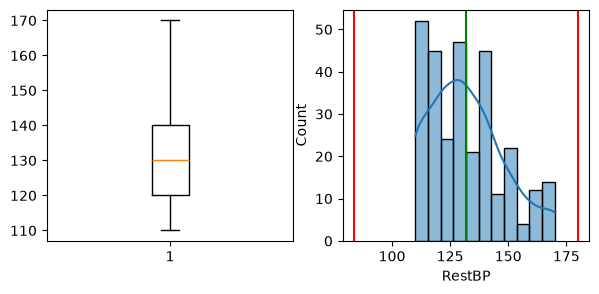

In [166]:
chkOutliers(data, 'RestBP')

In [167]:
replaceOutliers(data, 'Oldpeak')

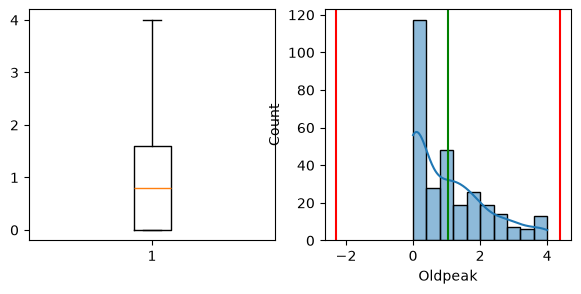

In [168]:
chkOutliers(data, 'Oldpeak')

In [169]:
replaceOutliers(data, 'MaxHR')

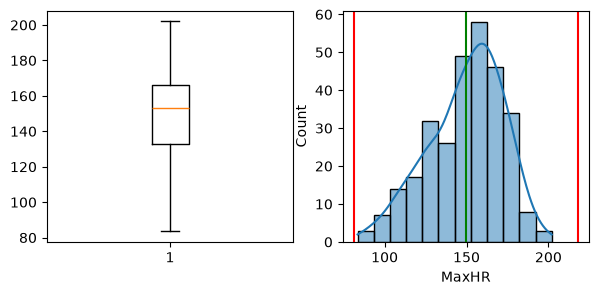

In [170]:
chkOutliers(data, 'MaxHR')

In [171]:
replaceOutliers(data, 'Chol')

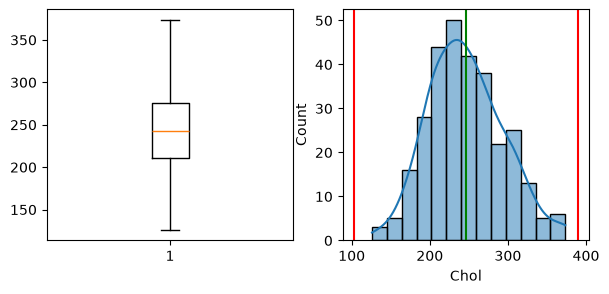

In [172]:
chkOutliers(data, 'Chol')

In [173]:
data['ChestPain'].unique()

array([0, 1, 2, 3], dtype=object)

In [174]:
data = data.replace({'typical':0, 'asymptomatic':1, 'nonanginal':2, 'nontypical':3})

In [175]:
data.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,0,145.0,233.0,1,2,150.0,0,2.3,3,0.0,0,No
1,2,67,1,1,160.0,286.0,0,2,108.0,1,1.5,2,3.0,1,Yes
2,3,67,1,1,120.0,229.0,0,2,129.0,1,2.6,2,2.0,2,Yes
3,4,37,1,2,130.0,250.0,0,0,187.0,0,3.5,3,0.0,1,No
4,5,41,0,3,130.0,204.0,0,2,172.0,0,1.4,1,0.0,1,No


In [176]:
data['Thal'].unique()

array([0, 1, 2], dtype=object)

In [177]:
data = data.replace({'fixed':0, 'normal':1, 'reversable':2})

In [178]:
data.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,0,145.0,233.0,1,2,150.0,0,2.3,3,0.0,0,No
1,2,67,1,1,160.0,286.0,0,2,108.0,1,1.5,2,3.0,1,Yes
2,3,67,1,1,120.0,229.0,0,2,129.0,1,2.6,2,2.0,2,Yes
3,4,37,1,2,130.0,250.0,0,0,187.0,0,3.5,3,0.0,1,No
4,5,41,0,3,130.0,204.0,0,2,172.0,0,1.4,1,0.0,1,No


In [186]:
data.info()

<class 'pandas.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  297 non-null    int64  
 1   Age         297 non-null    int64  
 2   Sex         297 non-null    int64  
 3   ChestPain   297 non-null    object 
 4   RestBP      297 non-null    float64
 5   Chol        297 non-null    float64
 6   Fbs         297 non-null    int64  
 7   RestECG     297 non-null    int64  
 8   MaxHR       297 non-null    float64
 9   ExAng       297 non-null    int64  
 10  Oldpeak     297 non-null    float64
 11  Slope       297 non-null    int64  
 12  Ca          297 non-null    float64
 13  Thal        297 non-null    object 
 14  AHD         297 non-null    str    
dtypes: float64(5), int64(7), object(2), str(1)
memory usage: 37.1+ KB


In [187]:
data['AHD'].value_counts()

AHD
No     160
Yes    137
Name: count, dtype: int64

In [179]:
X = data.drop(['Unnamed: 0','AHD'], axis=1)
y = data['AHD']

In [188]:
from imblearn.over_sampling import SMOTE

In [189]:
sm = SMOTE()
X, y = sm.fit_resample(X, y)
X.shape

(320, 13)

In [190]:
y.value_counts()

AHD
No     160
Yes    160
Name: count, dtype: int64

In [191]:
from sklearn.model_selection import train_test_split

In [192]:
X_train, X_test, y_train, y_test = train_test_split(X, y,random_state=7, test_size=0.2)

In [193]:
from sklearn.ensemble import RandomForestClassifier

In [194]:
model = RandomForestClassifier()
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [195]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

In [196]:
from sklearn.metrics import accuracy_score
print('Training accuracy:', accuracy_score(y_train, train_pred))
print('Testing accuracy:', accuracy_score(y_test, test_pred))

Training accuracy: 1.0
Testing accuracy: 0.859375
